In [101]:
### Libaries
import sklearn
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.table as tb
from sklearn.datasets import fetch_california_housing, fetch_openml
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import BaggingClassifier, ExtraTreesClassifier, RandomForestClassifier, AdaBoostClassifier, HistGradientBoostingClassifier, GradientBoostingRegressor, VotingClassifier, StackingClassifier
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.model_selection import GridSearchCV

In [29]:
### Random Seed
RANDOM_SEEDS = [1,2,3,4,5]

In [30]:
### Data
fashionMNIST = fetch_openml('Fashion-MNIST')
californiaHousing = fetch_california_housing()

In [31]:
# split from last hw iris_utils
def stratified_split(X, y, test_fraction=0.3, seed=0):
    """Seeded, class-proportional train/test split."""
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for k in np.unique(y):
        idx_k = np.where(y == k)[0]
        rng.shuffle(idx_k)
        n_test_k = int(round(len(idx_k) * test_fraction))
        test_idx.extend(idx_k[:n_test_k])
        train_idx.extend(idx_k[n_test_k:])
    train_idx, test_idx = np.array(train_idx), np.array(test_idx)
    rng.shuffle(train_idx)
    rng.shuffle(test_idx)
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

In [32]:
# split data
xtrs = []
xvals = []
ytrs = []
yvals = []
xtes = []
ytes = []

for seed in RANDOM_SEEDS:
    # take 15k needed ~ 1/4 of dataset
    X = fashionMNIST.data[:15001].to_numpy()
    y = fashionMNIST.target[:15001].to_numpy()

    # split into 10,000 train, 5,000 val
    xtr, xval, ytr, yval = stratified_split(X, y, test_fraction=1/3, seed=seed)

    # take test
    xte = fashionMNIST.data[60000:].to_numpy()
    yte = fashionMNIST.target[60000:].to_numpy()

    xtrs.append(xtr)
    xvals.append(xval)
    ytrs.append(ytr)
    yvals.append(yval)
    xtes.append(xte)
    ytes.append(yte)

In [33]:
### Part 1: Single CART trees

entropyTrees = []
entropyTrainAccuracies = []
entropyValidationAccuracies = []
entropyTimes = []
entropyLeaves = []
entropyActualDepths = []
giniTrees = []
giniTrainAccuracies = []
giniValidationAccuracies = []
giniTimes = []
giniLeaves = []
giniActualDepths = []

for l in range(len(RANDOM_SEEDS)):
    print(seed)
    depths = [2,4,6,8,10,12,15,20,None]
    currEntropyTrees = []
    currEntropyTrainAccuracies = []
    currEntropyValidationAccuracies = []
    currEntropyTimes = []
    currEntropyLeaves = []
    currEntropyActualDepths = []

    for depth in depths:
        start = time.time()

        # create and fit tree
        entropyTree = DecisionTreeClassifier(criterion='entropy', random_state=RANDOM_SEEDS[l], max_depth=depth)
        entropyTree.fit(xtrs[l], ytrs[l])

        # training accuracy
        entropyTreePredictions = entropyTree.predict(xtrs[l])
        entropyTrainAccuracy = accuracy_score(ytrs[l], entropyTreePredictions)

        # validation accuracy
        entropyTreePredictions = entropyTree.predict(xvals[l])
        entropyValidationAccuracy = accuracy_score(yvals[l], entropyTreePredictions)

        # update lists
        end = time.time()
        currEntropyTimes.append(end-start)
        currEntropyTrainAccuracies.append(entropyTrainAccuracy)
        currEntropyValidationAccuracies.append(entropyValidationAccuracy)
        currEntropyLeaves.append(entropyTree.get_n_leaves())
        currEntropyTrees.append(entropyTree)
        currEntropyActualDepths.append(entropyTree.get_depth())

    print("Entropy Done")
    currGiniTrees = []
    currGiniTrainAccuracies = []
    currGiniValidationAccuracies = []
    currGiniTimes = []
    currGiniLeaves = []
    currGiniActualDepths = []

    for depth in depths:
        start = time.time()

        # create and fit tree
        giniTree = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_SEEDS[l], max_depth=depth)
        giniTree.fit(xtrs[l], ytrs[l])
        
        # training accuracy
        giniTreePredictions = giniTree.predict(xtrs[l])
        giniTrainAccuracy = accuracy_score(ytrs[l], giniTreePredictions)

        # validation accuracy
        giniTreePredictions = giniTree.predict(xvals[l])
        giniValidationAccuracy = accuracy_score(yvals[l], giniTreePredictions)

        # update lists
        end = time.time()
        currGiniTimes.append(end-start)
        currGiniTrainAccuracies.append(giniTrainAccuracy)
        currGiniValidationAccuracies.append(giniValidationAccuracy)
        currGiniLeaves.append(giniTree.get_n_leaves())
        currGiniActualDepths.append(giniTree.get_depth())
        currGiniTrees.append(giniTree)

    print("Gini Done")
    entropyTrees.append(currEntropyTrees)
    entropyTrainAccuracies.append(currEntropyTrainAccuracies)
    entropyValidationAccuracies.append(currEntropyValidationAccuracies)
    entropyTimes.append(currEntropyTimes)
    entropyLeaves.append(currEntropyLeaves)
    entropyActualDepths.append(currEntropyActualDepths)
    giniTrees.append(currGiniTrees)
    giniTrainAccuracies.append(currGiniTrainAccuracies)
    giniValidationAccuracies.append(currGiniValidationAccuracies)
    giniTimes.append(currGiniTimes)
    giniLeaves.append(currGiniLeaves)
    giniActualDepths.append(currGiniActualDepths)


5
Entropy Done
Gini Done
5
Entropy Done
Gini Done
5
Entropy Done
Gini Done
5
Entropy Done
Gini Done
5
Entropy Done
Gini Done


In [34]:
def mean_std(vals):
    n = len(vals)
    mu = sum(vals) / n

    s = 0
    for val in vals:
        s += (val-mu)**2
    std = (s / (n - 1))**0.5
    return (mu,std)

def calcStats(vals):
    stats = []
    for i in range(len(depths)):
        valuesAcrossDepth = []
        for l in range(len(RANDOM_SEEDS)):
            valuesAcrossDepth.append(vals[l][i])
        stats.append(mean_std(valuesAcrossDepth))
    return stats
    
entropyTrainAccStats = calcStats(entropyTrainAccuracies)
entropyValidationAccStats = calcStats(entropyValidationAccuracies)
entropyTimeStats = calcStats(entropyTimes)
entropyLeaveStats= calcStats(entropyLeaves)
entropyAcDepthStats = calcStats(entropyActualDepths)
giniTrainAccStats = calcStats(giniTrainAccuracies)
giniValidationAccStats = calcStats(giniValidationAccuracies)
giniTimeStats = calcStats(giniTimes)
giniLeaveStats = calcStats(giniLeaves)
giniAcDepthStats = calcStats(giniActualDepths)

In [ ]:
### part 1b - how often the two criteria choose the same feature at the root and at depth 1–2
def getFeaturesAtDepth1_2(model):
    tree = model.tree_
    features = {}

    # root
    if tree.feature[0] != -2:
        features[""] = tree.feature[0]

    # depth 1
    left = tree.children_left[0]
    right = tree.children_right[0]

    if left != -1 and tree.feature[left] != -2:
        features["L"] = tree.feature[left]
    if right != -1 and tree.feature[right] != -2:
        features["R"] = tree.feature[right]

    # depth 2
    for node, path in [(left, "L"), (right, "R")]:
        if node == -1:
            continue

        left2 = tree.children_left[node]
        right2 = tree.children_right[node]

        if left2 != -1 and tree.feature[left2] != -2:
            features[path + "L"] = tree.feature[left2]
        if right2 != -1 and tree.feature[right2] != -2:
            features[path + "R"] = tree.feature[right2]

    return features

rootList = []
depth1List = []
depth2list = []

for l in range(len(RANDOM_SEEDS)):
    matches = [0, 0, 0]
    totals = [0, 0, 0]

    for entropyTree, giniTree in zip(entropyTrees[l], giniTrees[l]):
        entropyFeatures = getFeaturesAtDepth1_2(entropyTree)
        giniFeatures = getFeaturesAtDepth1_2(giniTree)

        # total positions for both trees
        paths = entropyFeatures.keys() | giniFeatures.keys()

        for path in paths:
            depth = len(path)
            totals[depth] += 1

            if path in entropyFeatures and path in giniFeatures:
                if entropyFeatures[path] == giniFeatures[path]:
                    matches[depth] += 1
                    
    # division by zero check
    if totals[0] > 0:
        rootList.append(matches[0] / totals[0])
    if totals[1] > 0:
        depth1List.append(matches[1] / totals[1])
    if totals[2] > 0:
        depth2list.append(matches[2] / totals[2])


rootMean, rootStd = mean_std(rootList)
depth1Mean, depth1Std = mean_std(depth1List)
depth2Mean, depth2Std = mean_std(depth2list)
totalmean, totalstd = mean_std(rootList + depth1List + depth2list)

print("Root agreement: {:.3f} ± {:.3f}".format(rootMean, rootStd))
print("Depth 1 agreement: {:.3f} ± {:.3f}".format(depth1Mean, depth1Std))
print("Depth 2 agreement: {:.3f} ± {:.3f}".format(depth2Mean, depth2Std))
print("Total agreement: {:.3f} ± {:.3f}".format(depth2Mean, depth2Std))

Root agreement: 0.000 ± 0.000
Depth 1 agreement: 0.000 ± 0.000
Depth 2 agreement: 0.050 ± 0.112
Total agreement: 0.050 ± 0.112


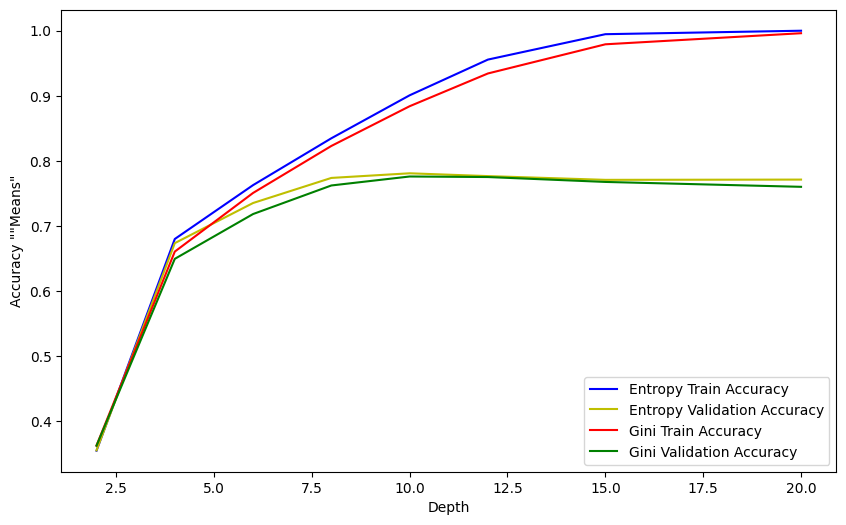

In [ ]:
### part 1b - train and validation accuracy vs. depth (one plot, both criteria)
fig, ax = plt.subplots(figsize=(10,6))
ax.plot(depths, [i[0] for i in entropyTrainAccStats], label='Entropy Train Accuracy', color='b')
ax.plot(depths, [i[0] for i in entropyValidationAccStats], label='Entropy Validation Accuracy', color='y')
ax.set_xlabel('Depth')
ax.set_ylabel('Accuracy "Means"')
ax.plot(depths, [i[0] for i in giniTrainAccStats], label='Gini Train Accuracy', color='r')
ax.plot(depths, [i[0] for i in giniValidationAccStats], label='Gini Validation Accuracy', color='g')
ax.legend(loc='lower right')


C:\Users\jafer\AppData\Local\Temp\ipykernel_24364\1816994661.py:24: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


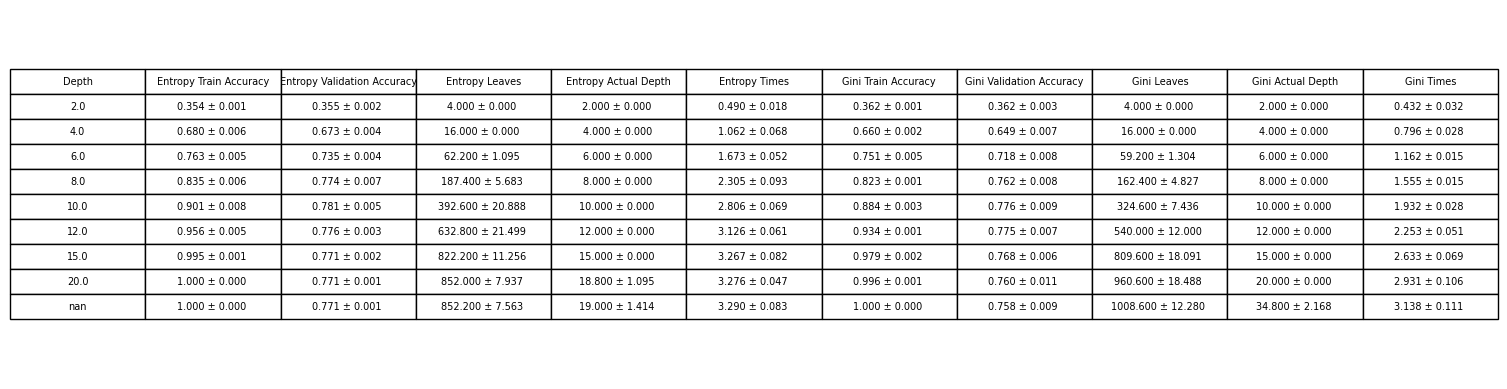

In [ ]:
### part 1b - training time, number of leaves and actual depth & mean ± std over 5 random seeds or subsamples
def combine(stats):
    return ["{:.3f} ± {:.3f} ".format(mu, std) for mu, std in stats]

table = pd.DataFrame({
    'Depth': depths,
    'Entropy Train Accuracy': combine(entropyTrainAccStats),
    'Entropy Validation Accuracy': combine(entropyValidationAccStats),
    'Entropy Leaves': combine(entropyLeaveStats),
    'Entropy Actual Depth': combine(entropyAcDepthStats),
    'Entropy Times': combine(entropyTimeStats),
    'Gini Train Accuracy': combine(giniTrainAccStats),
    'Gini Validation Accuracy': combine(giniValidationAccStats),
    'Gini Leaves': combine(giniLeaveStats),
    'Gini Actual Depth': combine(giniAcDepthStats),
    'Gini Times': combine(giniTimeStats)
})
fig, ax = plt.subplots()
ax.axis('off')
axtable = ax.table(cellText=table.values, colLabels=table.columns, loc='center', cellLoc='center')
axtable.auto_set_font_size(False)
axtable.set_fontsize(7)
axtable.scale(3, 1.5)
plt.tight_layout()
plt.show()


In [92]:
### part 1c pruning
import random
xtr = xtrs[0]
ytr = ytrs[0]

tree = DecisionTreeClassifier(criterion='gini', random_state=RANDOM_SEEDS[0])

path = tree.cost_complexity_pruning_path(xtr, ytr)
alphas = path.ccp_alphas
impurities = path.impurities
print(len(alphas))

# select say 20 values
useAlphas = []
# https://numpy.org/doc/stable/user/how-to-partition.html
indices = np.linspace(0, len(alphas) - 1, 20, dtype=int)
for i in indices:
    useAlphas.append(alphas[i])
useAlphas.sort()

782


In [95]:
validationAccuracies = []
leafCounts = []

for i,alpha in enumerate(useAlphas):
    print(i)
    ccpTree = DecisionTreeClassifier(criterion='gini', ccp_alpha = alpha, random_state=RANDOM_SEEDS[0])
    ccpTree.fit(xtr,ytr)
    predict = ccpTree.predict(xval)
    validationAccuracies.append(accuracy_score(predict, yval))
    leafCounts.append(ccpTree.get_n_leaves())

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19


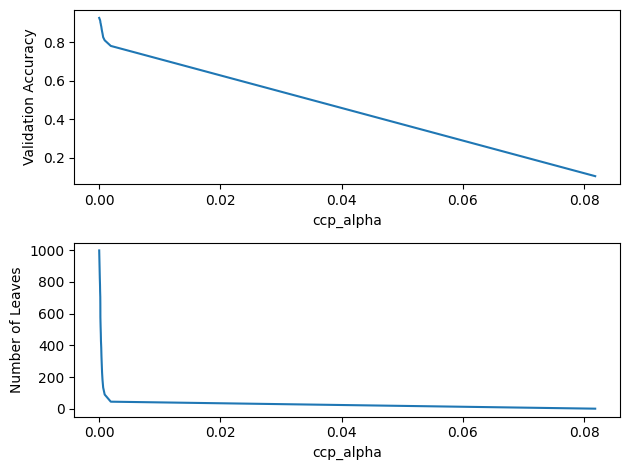

In [98]:
fig, ax = plt.subplots(2, 1)

ax[0].plot(useAlphas, validationAccuracies)
ax[0].set_xlabel('ccp_alpha')
ax[0].set_ylabel('Validation Accuracy')

ax[1].plot(useAlphas, leafCounts)
ax[1].set_xlabel('ccp_alpha')
ax[1].set_ylabel('Number of Leaves')

plt.tight_layout()
plt.show()

In [106]:
#https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
grid = GridSearchCV(
    DecisionTreeClassifier(
        criterion='gini',
        random_state=RANDOM_SEEDS[0]
    ),
    param_grid={'ccp_alpha': useAlphas},
    cv=5,
    scoring='accuracy',
)

grid.fit(xtr,ytr)
best = grid.best_params_["ccp_alpha"]

print("Optimal Alpha: {:.4f}".format(best))
print("Best Pruning Validation Accuracy {:.4f}".format(grid.best_estimator_.score(xval,yval)))

Optimal Alpha: 0.0005
Best Pruning Validation Accuracy 0.8450


In [105]:
### best depth was None
tree = DecisionTreeClassifier(criterion='entropy', random_state=RANDOM_SEEDS[0], max_depth=20)
tree.fit(xtr,ytr)
predict = tree.predict(xval)
print("Best Depth-Limited Tree Validation Accuracy : {:.4f}".format(accuracy_score(predict, yval)))

Best Depth-Limited Tree Validation Accuracy : 0.9264
